In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

We consider the State space model
$$ x_{t+1} = ax_t + v_t $$
$$ x_{t} = x_t + e_t $$


# 4a 

### Simple simulation

In [10]:
a = 0.4 
sigma2_v = 1
sigma2_e = 1

delta_v = np.sqrt(sigma2_v)
delta_t = np.sqrt(sigma2_e)

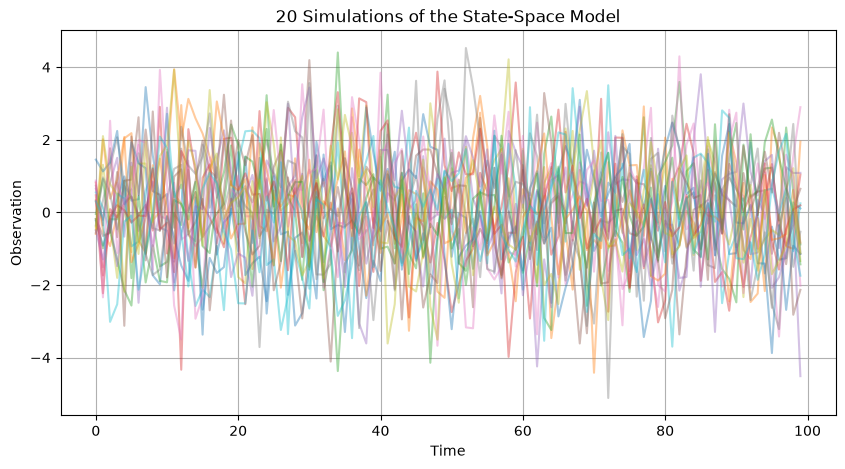

In [11]:
import numpy as np
import matplotlib.pyplot as plt


def simulate_model(a=0.4, sigma_v=1, sigma_e=1, T=100, n_simulations=20):
    '''
        a is the autoregressive parameter
        sigma_v is the standard deviation of the process noise
        sigma_e is the standard deviation of the observation noise
        T is the number of time steps
        n_simulations is the number of simulations to run
    '''
    X = np.zeros((n_simulations, T))
    Y = np.zeros((n_simulations, T))

    for i in range(n_simulations):
        for t in range(1, T):
            v = np.random.normal(0, sigma_v)
            X[i, t] = a * X[i, t-1] + v

        e = np.random.normal(0, sigma_e, T)
        Y[i] = X[i] + e

    return X, Y


def plot_simulations(Y):
    plt.figure(figsize=(10, 5))

    for y in Y:
        plt.plot(y, alpha=0.4)

    plt.xlabel("Time")
    plt.ylabel("Observation")
    plt.title(f"{len(Y)} Simulations of the State-Space Model")
    plt.grid(True)
    plt.show()


# Run simulation
np.random.seed(42)
X, Y = simulate_model()

# Plot results
plot_simulations(Y)

### Rewrite to prepare for EKF

Augmented state: [1.  0.4]
Predicted state: [1.4 0.4]
Augmented state .> [1.  0.4]
Predicted observation: 1.0
State Jacobian:
 [[0.4 1. ]
 [0.  1. ]]
Observation Jacobian:
 [[1 0]]
Control input: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]


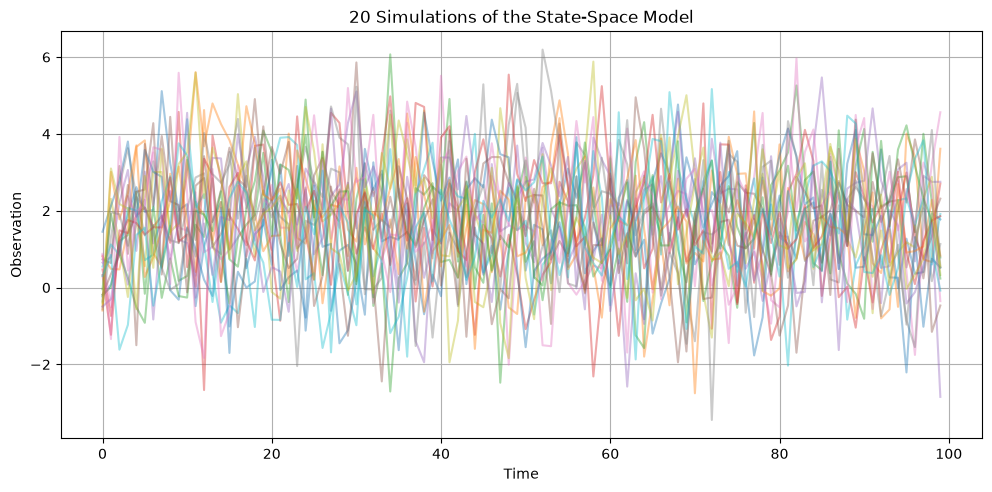

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Simulate the original model
# --------------------------------------------------

def simulate_model(u, a=0.4, sigma_v=1, sigma_e=1, n_simulations=20):
    """
    u: Known control input over time
    a: True autoregressive parameter
    sigma_v: Standard deviation of process noise
    sigma_e: Standard deviation of observation noise
    n_simulations: Number of simulations
    """
    T = len(u)

    X = np.zeros((n_simulations, T))
    Y = np.zeros((n_simulations, T))

    for i in range(n_simulations):
        for t in range(T - 1):
            v = np.random.normal(0, sigma_v)
            X[i, t + 1] = a * X[i, t] + u[t] + v

        e = np.random.normal(0, sigma_e, T)
        Y[i] = X[i] + e

    return X, Y


# --------------------------------------------------
# 2. Augmented state-space model
# --------------------------------------------------

def f(Z, u):
    """Nonlinear state transition function."""
    x, a = Z
    return np.array([a * x + u, a])


def h(Z):
    """Observation function."""
    print("Augmented state .>", Z)
    x, a = Z
    return x


# --------------------------------------------------
# 3. Jacobians for EKF
# --------------------------------------------------

def jacobian_f(Z):
    """Jacobian of the transition function."""
    x, a = Z
    return np.array([
        [a, x],
        [0, 1]
    ])


def jacobian_h(Z):
    """Jacobian of the observation function."""
    return np.array([[1, 0]])


# --------------------------------------------------
# 4. Plot simulations
# --------------------------------------------------

def plot_simulations(Y):
    fig, ax = plt.subplots(figsize=(10, 5))

    for y in Y:
        ax.plot(y, alpha=0.4)

    ax.set_xlabel("Time")
    ax.set_ylabel("Observation")
    ax.set_title(f"{len(Y)} Simulations of the State-Space Model")
    ax.grid(True)
    fig.tight_layout(pad=1)
    fig.savefig("assets/part_4a_simulation.png", bbox_inches="tight", pad_inches=0.1)
    plt.show()


# --------------------------------------------------
# 5. Run
# --------------------------------------------------

np.random.seed(42)

T = 100

# Example: constant control input
u = np.ones(T)

# Simulate system
X, Y = simulate_model(u)

# Noise covariance matrices
Q = np.diag([1, 0])
R = np.array([[1]])

# Example augmented state
Z = np.array([1.0, 0.4])

print("Augmented state:", Z)
print("Predicted state:", f(Z, u[0]))
print("Predicted observation:", h(Z))
print("State Jacobian:\n", jacobian_f(Z))
print("Observation Jacobian:\n", jacobian_h(Z))
print("Control input:", u)

plot_simulations(Y)
